# Lap times: exploratory data analysis

This notebook explores **only `data/raw/lap_times.csv`**. One row represents a
reported lap timing for one driver in one race. Its expected unique key is
`(season, round, driver_id, lap)`.

We investigate coverage, missing values, timing formats, duplicates, lap
continuity, unusual durations, and patterns within a race. The final section
saves a processed copy to `data/processed/laps/lap_times.csv`, including
`lap_time_seconds`, for use by subsequent notebooks. The source CSV remains
unchanged.

**Questions**
1. Which seasons, races, circuits, and drivers are represented?
2. Are identifiers, dates, positions, and timing values internally consistent?
3. Where are missing values and gaps concentrated?
4. How do timing distributions change by circuit and race lap?
5. Which observations need review before a later pace analysis?

Run cells from top to bottom. The final season may be a partial snapshot.
Without another source, coverage describes what is present; it cannot establish
whether every scheduled race or completed lap is available.

## 1. Setup and loading

Select a Python kernel with `pandas`, `matplotlib`, and `ipykernel` installed.
From the project root, install them if needed with
`python -m pip install -r requirements.txt ipykernel`.
No installation runs automatically inside this notebook.

In [1]:
from pathlib import Path
import math
import re

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 65)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})

# Support execution from the repository root, notebooks/, or a subdirectory.
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "raw" / "lap_times.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Run this notebook inside the f1-driver-vs-car repository.")

csv_path = project_root / "data" / "raw" / "lap_times.csv"
text_columns = ["race_name", "race_date", "race_start_time", "circuit_id",
                "circuit_name", "driver_id", "lap_time"]
raw = pd.read_csv(csv_path, dtype={column: "string" for column in text_columns},
                  low_memory=False)
if raw.empty:
    raise ValueError("The source CSV contains no lap timings.")

race_key = ["season", "round"]
driver_race_key = race_key + ["driver_id"]
lap_key = driver_race_key + ["lap"]
required_columns = set(lap_key + text_columns + ["position"])
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print(f"Source: {csv_path.relative_to(project_root)}")
print(f"Size: {csv_path.stat().st_size / 1024**2:,.1f} MiB")
print(f"pandas {pd.__version__}")

Matplotlib is building the font cache; this may take a moment.


Source: data\raw\lap_times.csv
Size: 63.2 MiB
pandas 3.0.3


## 2. Structure and first observations

`position` is the reported position at a lap, not the finishing position.
`lap_time` is a duration, while `race_start_time` is an event start time.
Driver and circuit identifiers should remain strings.

| Column | Meaning |
|---|---|
| `season`, `round` | Race identifier within a season |
| `race_name`, `race_date`, `race_start_time` | Repeated race metadata |
| `circuit_id`, `circuit_name` | Circuit identifier and label |
| `driver_id` | Driver identifier |
| `lap` | Reported lap number |
| `position` | Reported position at that lap; may be missing |
| `lap_time` | Original reported duration as text |

In [2]:
overview = pd.Series({
    "Rows": len(raw),
    "Columns": raw.shape[1],
    "Seasons": raw["season"].nunique(),
    "Races": len(raw[race_key].drop_duplicates()),
    "Circuits": raw["circuit_id"].nunique(),
    "Drivers": raw["driver_id"].nunique(),
    "Driver-race combinations": len(raw[driver_race_key].drop_duplicates()),
    "First date (source text)": raw["race_date"].min(),
    "Last date (source text)": raw["race_date"].max(),
}, name="Value")
display(overview.to_frame())
display(raw.head())
display(raw.tail())

,Value
Rows,639293
Columns,11
Seasons,31
Races,588
Circuits,42
Drivers,149
Driver-race combinations,11938
First date (source text),1996-03-10
Last date (source text),2026-11-08


,season,round,race_name,race_date,race_start_time,circuit_id,circuit_name,driver_id,lap,position,lap_time
0,1996,1,Australian Grand Prix,1996-03-10,<NA>,albert_park,Albert Park Grand Prix Circuit,villeneuve,1,1.000,1:43.702
1,1996,1,Australian Grand Prix,1996-03-10,<NA>,albert_park,Albert Park Grand Prix Circuit,damon_hill,1,2.000,1:44.243
2,1996,1,Australian Grand Prix,1996-03-10,<NA>,albert_park,Albert Park Grand Prix Circuit,irvine,1,3.000,1:44.981
3,1996,1,Australian Grand Prix,1996-03-10,<NA>,albert_park,Albert Park Grand Prix Circuit,michael_schumacher,1,4.000,1:45.188
4,1996,1,Australian Grand Prix,1996-03-10,<NA>,albert_park,Albert Park Grand Prix Circuit,alesi,1,5.000,1:46.506


,season,round,race_name,race_date,race_start_time,circuit_id,circuit_name,driver_id,lap,position,lap_time
639288,2026,20,Brazilian Grand Prix,2026-11-08,17:00:00Z,interlagos,Autódromo José Carlos Pace,russell,71,4.000,1:29.283
639289,2026,20,Brazilian Grand Prix,2026-11-08,17:00:00Z,interlagos,Autódromo José Carlos Pace,antonelli,71,5.000,1:29.159
639290,2026,20,Brazilian Grand Prix,2026-11-08,17:00:00Z,interlagos,Autódromo José Carlos Pace,piastri,71,6.000,1:30.505
639291,2026,20,Brazilian Grand Prix,2026-11-08,17:00:00Z,interlagos,Autódromo José Carlos Pace,leclerc,71,7.000,1:32.037
639292,2026,20,Brazilian Grand Prix,2026-11-08,17:00:00Z,interlagos,Autódromo José Carlos Pace,lawson,71,8.000,1:32.109


In [3]:
column_profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
    "distinct_non_null": raw.nunique(),
    "memory_MiB": raw.memory_usage(index=False, deep=True).div(1024**2),
})
display(column_profile)
raw.info(memory_usage="deep")
display(raw.describe(include="number"))

,dtype,non_null,missing,missing_pct,distinct_non_null,memory_MiB
season,int64,639293,0,0.000,31,4.877
round,int64,639293,0,0.000,24,4.877
race_name,string,639293,0,0.000,45,16.498
race_date,string,639293,0,0.000,588,10.974
race_start_time,string,488342,150951,23.612,34,9.145
circuit_id,string,639293,0,0.000,42,10.107
circuit_name,string,639293,0,0.000,42,18.685
driver_id,string,639293,0,0.000,149,9.536
lap,int64,639293,0,0.000,87,4.877
position,float64,639277,16,0.003,24,4.877


<class 'pandas.DataFrame'>
RangeIndex: 639293 entries, 0 to 639292
Data columns (total 11 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   season           639293 non-null  int64  
 1   round            639293 non-null  int64  
 2   race_name        639293 non-null  string 
 3   race_date        639293 non-null  string 
 4   race_start_time  488342 non-null  string 
 5   circuit_id       639293 non-null  string 
 6   circuit_name     639293 non-null  string 
 7   driver_id        639293 non-null  string 
 8   lap              639293 non-null  int64  
 9   position         639277 non-null  float64
 10  lap_time         639293 non-null  string 
dtypes: float64(1), int64(3), string(7)
memory usage: 104.2 MB


,season,round,lap,position
count,"639,293.000","639,293.000","639,293.000","639,277.000"
mean,"2,012.215",10.167,30.052,9.690
std,8.800,5.667,18.402,5.533
min,"1,996.000",1.000,1.000,1.000
25%,"2,005.000",5.000,14.000,5.000
50%,"2,013.000",10.000,29.000,9.000
75%,"2,020.000",15.000,44.000,14.000
max,"2,026.000",24.000,87.000,24.000


## 3. Missing values

Do not fill missing positions with a mean or carry the previous position
forward. Missing start times may reflect historical availability and need not
invalidate an otherwise usable timing. The heatmap below shows whether
missingness is concentrated in particular seasons.

,missing,missing_pct
race_start_time,150951,23.612
position,16,0.003
season,0,0.000
race_name,0,0.000
round,0,0.000
circuit_id,0,0.000
race_date,0,0.000
circuit_name,0,0.000
driver_id,0,0.000
lap,0,0.000


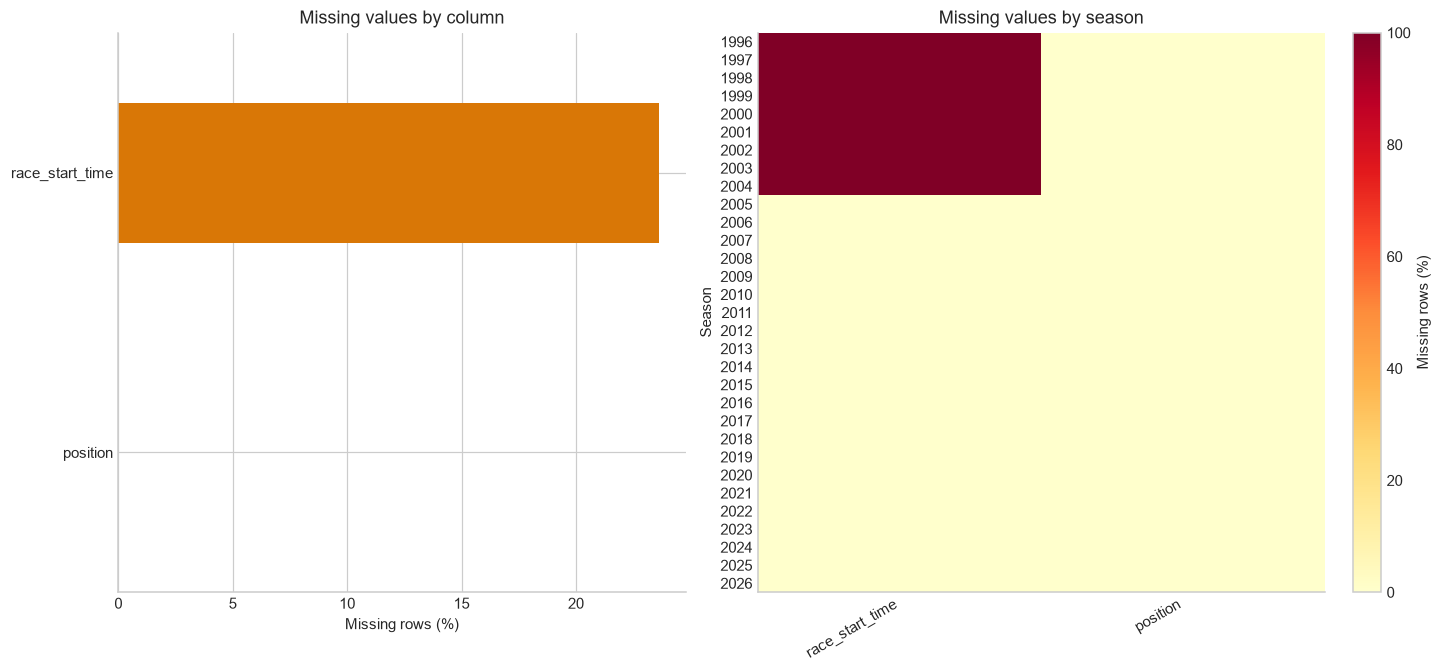

,season,round,driver_id,lap,position,lap_time
212654,2008,4,bourdais,6,NaN,1:25.999
241612,2009,13,alguersuari,17,NaN,1:27.846
242148,2009,13,buemi,50,NaN,1:25.564
252560,2010,6,bruno_senna,58,NaN,1:20.130
252724,2010,6,chandhok,69,NaN,1:19.553
252725,2010,6,trulli,69,NaN,1:19.340
340983,2014,1,massa,2,NaN,1:40.287
341417,2014,1,vettel,26,NaN,1:37.064
341486,2014,1,maldonado,30,NaN,1:34.766
341869,2014,1,jules_bianchi,55,NaN,1:35.635


In [4]:
missing_summary = column_profile[["missing", "missing_pct"]].sort_values(
    "missing", ascending=False)
display(missing_summary)

columns_with_missing = missing_summary.index[missing_summary["missing"].gt(0)].tolist()
if columns_with_missing:
    missing_by_season = (raw[columns_with_missing].isna()
                         .groupby(raw["season"]).mean().mul(100))
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout="constrained")
    missing_summary.loc[columns_with_missing, "missing_pct"].sort_values().plot.barh(
        ax=axes[0], color="#d97706")
    axes[0].set(xlabel="Missing rows (%)", ylabel="", title="Missing values by column")
    image = axes[1].imshow(missing_by_season, aspect="auto", vmin=0, vmax=100,
                           cmap="YlOrRd")
    axes[1].set_xticks(range(len(columns_with_missing)), columns_with_missing,
                       rotation=30, ha="right")
    axes[1].set_yticks(range(len(missing_by_season)), missing_by_season.index)
    axes[1].set(title="Missing values by season", ylabel="Season")
    axes[1].grid(False)
    fig.colorbar(image, ax=axes[1], label="Missing rows (%)")
    plt.show()
else:
    print("No missing values were found.")

display(raw.loc[raw["position"].isna(), lap_key + ["position", "lap_time"]])

## 4. Duplicate keys and internal validity

Exact duplicates repeat every field. Repeated lap keys may instead contain
conflicting values and require investigation. We also check positive integer
lap numbers and positions, dates, whitespace, and consistency of metadata
repeated across rows belonging to the same race.

In [5]:
exact_duplicate_mask = raw.duplicated()
repeated_key_mask = raw.duplicated(lap_key, keep=False)
numeric_values = raw[["season", "round", "lap", "position"]].apply(
    pd.to_numeric, errors="coerce")
invalid_numeric = (numeric_values.le(0) | numeric_values.mod(1).ne(0)) & numeric_values.notna()
unparseable_numeric = raw[numeric_values.columns].notna() & numeric_values.isna()
parsed_dates = pd.to_datetime(raw["race_date"], format="%Y-%m-%d", errors="coerce")

integrity_checks = pd.Series({
    "Exact duplicate rows (extra copies)": int(exact_duplicate_mask.sum()),
    "Rows belonging to repeated lap keys": int(repeated_key_mask.sum()),
    "Rows missing any lap-key field": int(raw[lap_key].isna().any(axis=1).sum()),
    "Rows with non-positive or fractional numeric fields": int(invalid_numeric.any(axis=1).sum()),
    "Rows with unparseable numeric fields": int(unparseable_numeric.any(axis=1).sum()),
    "Non-null dates that could not be parsed": int((raw["race_date"].notna() & parsed_dates.isna()).sum()),
}, name="Rows")
display(integrity_checks.to_frame())
display(raw.loc[repeated_key_mask].head(20))

text_checks = pd.DataFrame({
    "whitespace_at_edges": [int(raw[c].ne(raw[c].str.strip()).fillna(False).sum())
                            for c in text_columns],
    "blank_non_null_strings": [int(raw[c].str.strip().eq("").fillna(False).sum())
                               for c in text_columns],
}, index=text_columns)
display(text_checks)

metadata_columns = ["race_name", "race_date", "race_start_time", "circuit_id", "circuit_name"]
metadata_counts = raw.groupby(race_key, dropna=False)[metadata_columns].nunique(dropna=False)
metadata_conflicts = metadata_counts.gt(1).any(axis=1)
print(f"Races with conflicting metadata: {metadata_conflicts.sum():,}")
display(metadata_counts.loc[metadata_conflicts].head(20))

,Rows
Exact duplicate rows (extra copies),0
Rows belonging to repeated lap keys,0
Rows missing any lap-key field,0
Rows with non-positive or fractional numeric fields,0
Rows with unparseable numeric fields,0
Non-null dates that could not be parsed,0


,season,round,race_name,race_date,race_start_time,circuit_id,circuit_name,driver_id,lap,position,lap_time


,whitespace_at_edges,blank_non_null_strings
race_name,0,0
race_date,0,0
race_start_time,0,0
circuit_id,0,0
circuit_name,0,0
driver_id,0,0
lap_time,0,0


Races with conflicting metadata: 0


,,race_name,race_date,race_start_time,circuit_id,circuit_name
season,round,,,,,


## 5. Parse timing durations without losing valid formats

The source can contain seconds (`58.160`), minutes and seconds (`1:43.702`),
or hours, minutes and seconds (`2:05:05.152`). A parser restricted to a single
format would lose valid observations. We retain the original text and add
`lap_time_seconds` to an analysis copy. Invalid formats remain missing and are
listed explicitly; no rows are dropped.

In [6]:
colon_count = raw["lap_time"].str.count(":")
format_name = colon_count.map({0: "seconds", 1: "minutes:seconds", 2: "hours:minutes:seconds"})
format_name = format_name.fillna("missing or unsupported")
format_summary = (raw.assign(time_format=format_name)
                  .groupby("time_format", dropna=False)
                  .agg(rows=("lap_time", "size"), example=("lap_time", "first")))
format_summary["share_pct"] = format_summary["rows"].div(len(raw)).mul(100)
display(format_summary)

duration_pattern = re.compile(r"(?:[0-9]+:){0,2}[0-9]{1,2}\.[0-9]{3}")

def lap_time_to_seconds(value):
    '''Parse a reported duration; reject invalid formats and clock components.'''
    if pd.isna(value) or duration_pattern.fullmatch(value) is None:
        return float("nan")
    parts = value.split(":")
    if float(parts[-1]) >= 60 or (len(parts) == 3 and int(parts[-2]) >= 60):
        return float("nan")
    total = 0.0
    for part in parts:
        total = total * 60 + float(part)
    return total

# Small reference checks protect the three distinct source formats.
for text, expected in [("58.160", 58.160), ("1:43.702", 103.702),
                       ("2:05:05.152", 7505.152), ("53:24.155", 3204.155)]:
    assert math.isclose(lap_time_to_seconds(text), expected, abs_tol=1e-9)
assert math.isnan(lap_time_to_seconds("1:75.000"))

df = raw.copy()
df["race_date_parsed"] = parsed_dates
df["lap_time_seconds"] = df["lap_time"].map(lap_time_to_seconds)
invalid_time_mask = df["lap_time_seconds"].isna() | df["lap_time_seconds"].le(0)
print(f"Unusable timing durations: {invalid_time_mask.sum():,}")
display(df.loc[invalid_time_mask, lap_key + ["lap_time"]].head(20))
display(df[["lap_time", "lap_time_seconds"]].sample(min(8, len(df)), random_state=42))

,rows,example,share_pct
time_format,,,
hours:minutes:seconds,43,2:05:05.152,0.007
minutes:seconds,638093,1:43.702,99.812
seconds,1157,58.160,0.181


Unusable timing durations: 0


,season,round,driver_id,lap,lap_time


,lap_time,lap_time_seconds
390482,1:51.048,111.048
447701,1:12.329,72.329
223812,1:37.920,97.920
123930,1:19.176,79.176
36452,1:27.398,87.398
567723,1:33.162,93.162
582635,1:37.741,97.741
387584,1:38.130,98.130


## 6. Coverage by season, circuit, and driver

Counts below represent observed timings, not an external calendar or an
expected number of participants. The latest season can have fewer races
because collection is ongoing. Driver lap counts measure exposure in this
dataset, not performance.

,lap_timings,observed_races,drivers,circuits,first_date,last_date
season,,,,,,
1996,14431,16,24,16,1996-03-10,1996-10-13
1997,17206,17,26,17,1997-03-09,1997-10-26
1998,16175,16,23,16,1998-03-08,1998-11-01
1999,15804,16,24,16,1999-03-07,1999-10-31
2000,17977,17,23,17,2000-03-12,2000-10-22
2001,17357,17,26,17,2001-03-04,2001-10-14
2002,17350,17,23,17,2002-03-03,2002-10-13
2003,16043,16,24,16,2003-03-09,2003-10-12
2004,18608,18,25,18,2004-03-07,2004-10-24


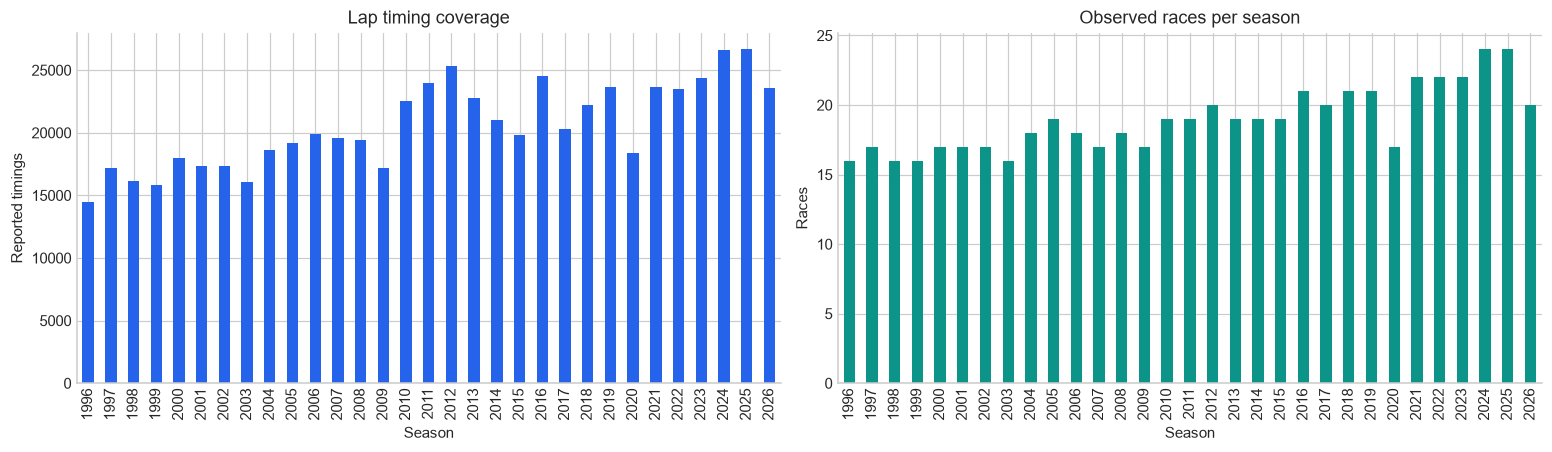

In [7]:
races = df[race_key + metadata_columns].drop_duplicates()
season_summary = df.groupby("season").agg(
    lap_timings=("lap", "size"),
    observed_races=("round", "nunique"),
    drivers=("driver_id", "nunique"),
    circuits=("circuit_id", "nunique"),
    first_date=("race_date_parsed", "min"),
    last_date=("race_date_parsed", "max"),
)
display(season_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
season_summary["lap_timings"].plot.bar(ax=axes[0], color="#2563eb")
season_summary["observed_races"].plot.bar(ax=axes[1], color="#0d9488")
axes[0].set(title="Lap timing coverage", xlabel="Season", ylabel="Reported timings")
axes[1].set(title="Observed races per season", xlabel="Season", ylabel="Races")
plt.show()

,circuit_name,lap_timings,seasons,drivers,observed_races
circuit_id,,,,,
silverstone,Silverstone Circuit,31853,31,130,32
catalunya,Circuit de Barcelona-Catalunya,36053,31,127,31
hungaroring,Hungaroring,40473,31,129,31
monza,Autodromo Nazionale di Monza,29354,31,130,31
monaco,Circuit de Monaco,39003,30,129,30
interlagos,Autódromo José Carlos Pace,37148,30,129,30
spa,Circuit de Spa-Francorchamps,21552,29,121,29
albert_park,Albert Park Grand Prix Circuit,26780,29,127,29
villeneuve,Circuit Gilles Villeneuve,33788,28,128,28


,lap_timings,seasons,first_season,last_season,observed_races
driver_id,,,,,
alonso,24032,23,2001,2026,439
hamilton,22825,20,2007,2026,394
raikkonen,18623,19,2001,2021,339
button,16272,18,2000,2017,299
perez,16521,15,2011,2026,295
vettel,16428,16,2007,2022,292
barrichello,14463,16,1996,2011,266
bottas,14613,13,2013,2026,264
massa,14855,15,2002,2017,262


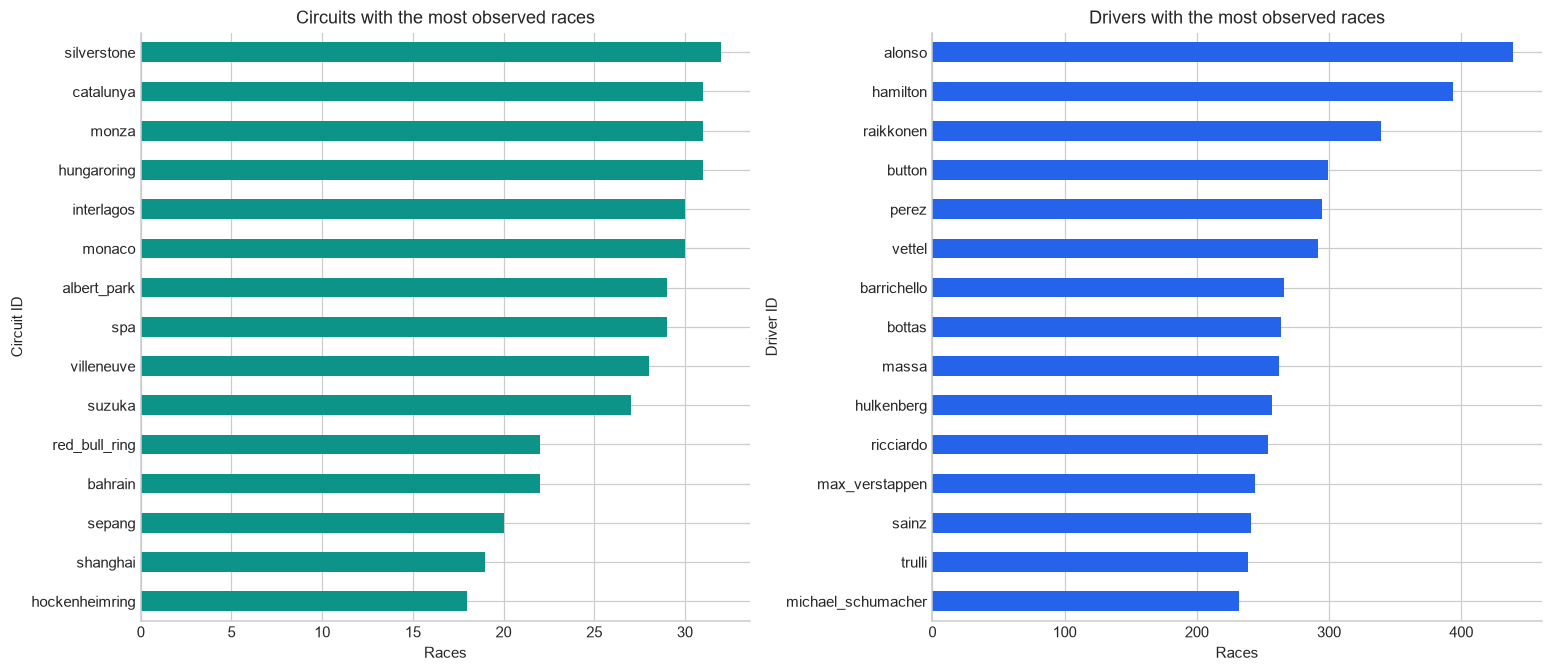

In [8]:
circuit_summary = df.groupby("circuit_id").agg(
    circuit_name=("circuit_name", "first"),
    lap_timings=("lap", "size"), seasons=("season", "nunique"),
    drivers=("driver_id", "nunique"),
)
circuit_race_counts = df[race_key + ["circuit_id"]].drop_duplicates().groupby("circuit_id").size()
circuit_summary["observed_races"] = circuit_race_counts
circuit_summary = circuit_summary.sort_values("observed_races", ascending=False)

driver_summary = df.groupby("driver_id").agg(
    lap_timings=("lap", "size"), seasons=("season", "nunique"),
    first_season=("season", "min"), last_season=("season", "max"),
)
driver_summary["observed_races"] = df[driver_race_key].drop_duplicates().groupby("driver_id").size()
driver_summary = driver_summary.sort_values("observed_races", ascending=False)
display(circuit_summary.head(15))
display(driver_summary.head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
circuit_summary.head(15)["observed_races"].sort_values().plot.barh(ax=axes[0], color="#0d9488")
driver_summary.head(15)["observed_races"].sort_values().plot.barh(ax=axes[1], color="#2563eb")
axes[0].set(title="Circuits with the most observed races", xlabel="Races", ylabel="Circuit ID")
axes[1].set(title="Drivers with the most observed races", xlabel="Races", ylabel="Driver ID")
plt.show()

## 7. Timing distributions and unusual durations

The full range includes very long observations. These can reflect a race
interruption or another timing issue; duration alone cannot establish the
cause. The second histogram zooms to the 1st–99th percentile **for display
only**. No observations are removed from `df`.

Pooled times also mix circuits, years, weather, traffic, tyres, and race
conditions. They must not be interpreted as a driver ranking.

,lap_time_seconds
count,"639,293.000"
mean,95.795
std,76.602
min,55.404
0.1%,58.544
1%,69.921
5%,74.725
25%,81.963
50%,90.616
75%,101.705


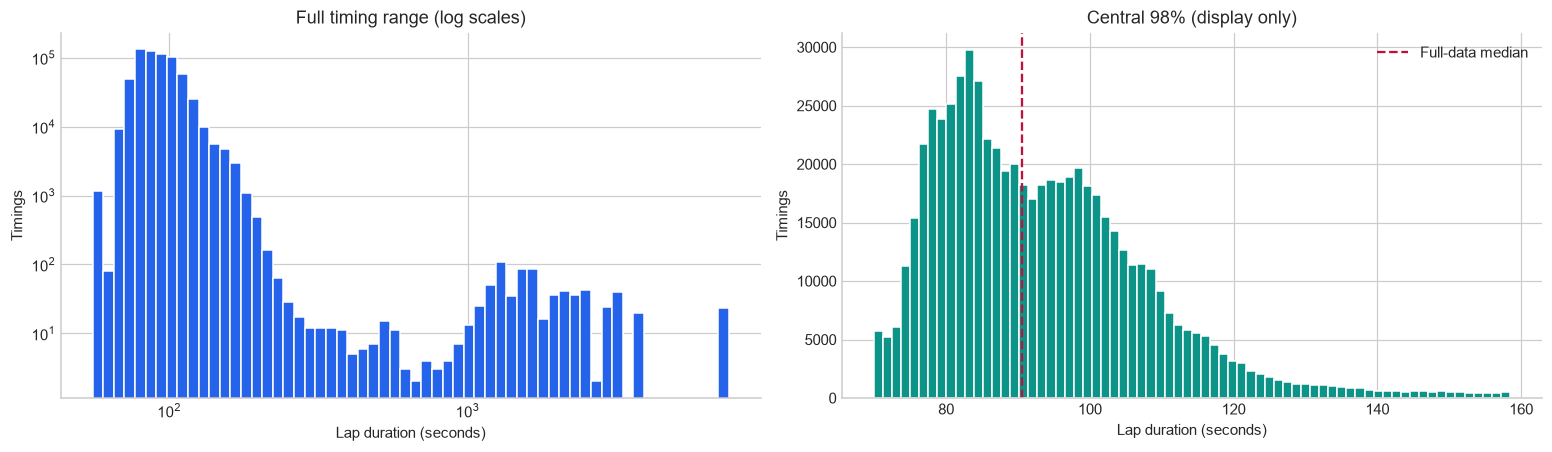

Zoom excludes 12,781 valid timings from this panel only.


In [9]:
valid_times = df.loc[~invalid_time_mask, "lap_time_seconds"]
if valid_times.empty:
    raise ValueError("No positive, parseable timings are available for plots.")
display(valid_times.describe(percentiles=[.001, .01, .05, .25, .5, .75, .95, .99, .999]).to_frame())

low, high = valid_times.quantile([.01, .99])
log_low, log_high = math.log10(valid_times.min()), math.log10(valid_times.max())
log_bins = [10 ** (log_low + (log_high - log_low) * index / 60) for index in range(61)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
axes[0].hist(valid_times, bins=log_bins, color="#2563eb", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set(title="Full timing range (log scales)", xlabel="Lap duration (seconds)", ylabel="Timings")
zoom = valid_times.between(low, high)
axes[1].hist(valid_times.loc[zoom], bins=70, color="#0d9488", edgecolor="white")
axes[1].axvline(valid_times.median(), color="#be123c", linestyle="--", label="Full-data median")
axes[1].set(title="Central 98% (display only)", xlabel="Lap duration (seconds)", ylabel="Timings")
axes[1].legend()
plt.show()
print(f"Zoom excludes {int((~zoom).sum()):,} valid timings from this panel only.")

In [10]:
duration_review = pd.DataFrame({
    "threshold_seconds": [180, 300, 600, 3600],
    "timings_above_threshold": [int(valid_times.gt(value).sum()) for value in [180, 300, 600, 3600]],
})
duration_review["share_pct"] = duration_review["timings_above_threshold"].div(len(df)).mul(100)
display(duration_review)
timing_columns = race_key + ["race_name", "driver_id", "lap", "position", "lap_time", "lap_time_seconds"]
display(Markdown("**Ten shortest reported timings**"))
display(df.loc[~invalid_time_mask].nsmallest(10, "lap_time_seconds")[timing_columns])
display(Markdown("**Ten longest reported timings**"))
display(df.loc[~invalid_time_mask].nlargest(10, "lap_time_seconds")[timing_columns])

# Identify whether long timings cluster among several drivers on the same race lap.
long_duration_groups = (df.loc[df["lap_time_seconds"].gt(300)]
    .groupby(race_key + ["race_name", "lap"])
    .agg(timings=("driver_id", "size"), drivers=("driver_id", "nunique"),
         min_seconds=("lap_time_seconds", "min"), max_seconds=("lap_time_seconds", "max"))
    .sort_values("drivers", ascending=False))
display(long_duration_groups.head(15))

,threshold_seconds,timings_above_threshold,share_pct
0,180,2180,0.341
1,300,787,0.123
2,600,705,0.110
3,3600,43,0.007


**Ten shortest reported timings**

,season,round,race_name,driver_id,lap,position,lap_time,lap_time_seconds
489754,2020,16,Sakhir Grand Prix,russell,80,14.000,55.404,55.404
489803,2020,16,Sakhir Grand Prix,russell,83,12.000,56.319,56.319
489657,2020,16,Sakhir Grand Prix,russell,75,2.000,56.393,56.393
489674,2020,16,Sakhir Grand Prix,russell,76,2.000,56.442,56.442
489819,2020,16,Sakhir Grand Prix,russell,84,11.000,56.499,56.499
489623,2020,16,Sakhir Grand Prix,russell,73,2.000,56.514,56.514
489770,2020,16,Sakhir Grand Prix,russell,81,13.000,56.542,56.542
489402,2020,16,Sakhir Grand Prix,bottas,60,2.000,56.563,56.563
489607,2020,16,Sakhir Grand Prix,russell,72,3.000,56.563,56.563
489385,2020,16,Sakhir Grand Prix,bottas,59,2.000,56.613,56.613


**Ten longest reported timings**

,season,round,race_name,driver_id,lap,position,lap_time,lap_time_seconds
277267,2011,7,Canadian Grand Prix,heidfeld,25,4.000,2:05:07.547,"7,507.547"
277266,2011,7,Canadian Grand Prix,massa,25,3.000,2:05:06.656,"7,506.656"
277268,2011,7,Canadian Grand Prix,petrov,25,5.000,2:05:06.243,"7,506.243"
277265,2011,7,Canadian Grand Prix,kobayashi,25,2.000,2:05:06.095,"7,506.095"
277264,2011,7,Canadian Grand Prix,vettel,25,1.000,2:05:05.152,"7,505.152"
277270,2011,7,Canadian Grand Prix,webber,25,7.000,2:05:05.034,"7,505.034"
277271,2011,7,Canadian Grand Prix,alonso,25,8.000,2:05:04.226,"7,504.226"
277269,2011,7,Canadian Grand Prix,resta,25,6.000,2:05:03.980,"7,503.980"
277272,2011,7,Canadian Grand Prix,rosa,25,9.000,2:05:03.795,"7,503.795"
277274,2011,7,Canadian Grand Prix,button,25,11.000,2:05:03.775,"7,503.775"


timings  drivers  min_seconds  \
season round race_name                lap                                  
2010   17    Korean Grand Prix        4         24       24    2,920.458   
2012   2     Malaysian Grand Prix     9         23       23    3,131.997   
2011   7     Canadian Grand Prix      25        23       23    7,469.869   
2014   15    Japanese Grand Prix      3         21       21    1,264.753   
2026   13    Italian Grand Prix       4         21       21    1,948.683   
       12    Dutch Grand Prix         3         20       20    1,701.681   
2020   15    Bahrain Grand Prix       2         19       19    1,327.924   
2021   10    British Grand Prix       3         19       19    2,227.083   
       21    Saudi Arabian Grand Prix 14        19       19    1,185.303   
2023   19    Mexico City Grand Prix   35        18       18    1,329.714   
2014   9     British Grand Prix       2         18       18    3,667.384   
2013   6     Monaco Grand Prix        46        18       18    1,512.835   
2016   20    Brazilian Grand Prix     21        18       18    2,116.816   
2024   4     Japanese Grand Prix      2         18       18    1,699.553   
2022   18    Japanese Grand Prix      3         18       18      541.634   

                                           max_seconds  
season round race_name                lap               
2010   17    Korean Grand Prix        4      2,942.501  
2012   2     Malaysian Grand Prix     9      3,138.842  
2011   7     Canadian Grand Prix      25     7,507.547  
2014   15    Japanese Grand Prix      3      1,300.684  
2026   13    Italian Grand Prix       4      1,958.319  
       12    Dutch Grand Prix         3      1,770.856  
2020   15    Bahrain Grand Prix       2      1,354.973  
2021   10    British Grand Prix       3      2,253.574  
       21    Saudi Arabian Grand Prix 14     1,201.043  
2023   19    Mexico City Grand Prix   35     1,340.297  
2014   9     British Grand Prix       2      3,803.459  
2013   6     Monaco Grand Prix        46     1,527.110  
2016   20    Brazilian Grand Prix     21     2,126.744  
2024   4     Japanese Grand Prix      2      1,714.647  
2022   18    Japanese Grand Prix      3        553.758

### Circuit context

Compare distributions separately by circuit rather than applying one global
outlier cutoff. Even within a circuit ID, layouts and regulations can change
over time. The boxplots hide flier markers for readability; they still use
all positive parsed observations to calculate quartiles and whiskers.

,timings,median_seconds,mean_seconds,p05_seconds,p95_seconds
circuit_id,,,,,
red_bull_ring,27114,71.857,74.183,68.764,89.922
interlagos,37148,78.045,85.358,73.457,112.438
villeneuve,33788,79.903,89.015,75.897,115.157
monaco,39003,80.880,88.787,76.288,115.785
hungaroring,40473,84.607,87.383,80.473,102.928
catalunya,36053,86.226,88.284,79.006,108.073
monza,29354,87.348,92.114,83.528,106.347
albert_park,26780,92.344,98.956,83.066,132.652
silverstone,31853,93.657,102.068,82.748,128.025


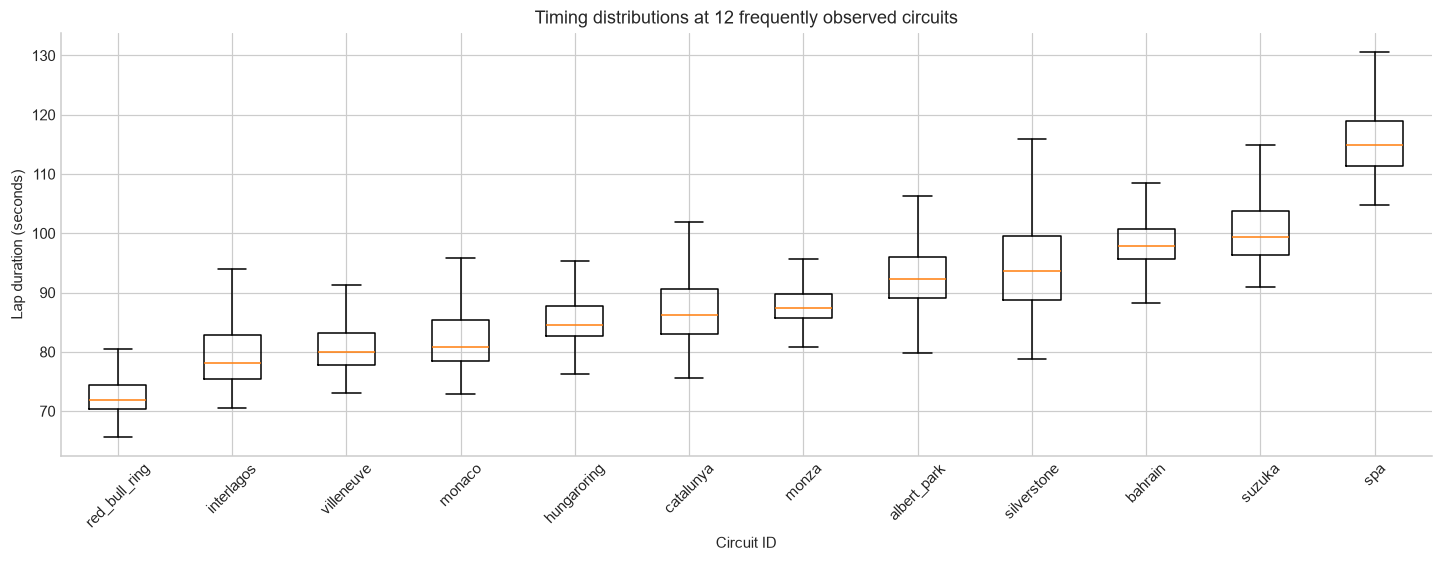

In [11]:
top_circuit_ids = circuit_summary.head(12).index.tolist()
circuit_time_summary = (df.loc[~invalid_time_mask]
    .groupby("circuit_id")["lap_time_seconds"]
    .agg(timings="size", median_seconds="median", mean_seconds="mean",
         p05_seconds=lambda values: values.quantile(.05),
         p95_seconds=lambda values: values.quantile(.95)))
display(circuit_time_summary.loc[top_circuit_ids].sort_values("median_seconds"))

ordered_circuits = circuit_time_summary.loc[top_circuit_ids].sort_values("median_seconds").index
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
ax.boxplot([df.loc[df["circuit_id"].eq(circuit) & ~invalid_time_mask, "lap_time_seconds"]
            for circuit in ordered_circuits],
           tick_labels=ordered_circuits, showfliers=False)
ax.tick_params(axis="x", rotation=45)
ax.set(title="Timing distributions at 12 frequently observed circuits",
       xlabel="Circuit ID", ylabel="Lap duration (seconds)")
plt.show()

## 8. Lap sequence continuity and positions

After sorting by the expected key, a difference greater than one identifies
an internal gap in the reported sequence. A first observed lap greater than
one is listed separately. Neither check identifies the reason or proves that
the driver completed the missing laps. We do not interpolate timing values.

We cannot detect missing trailing laps or verify the official completed-lap
count using this CSV alone.

In [12]:
ordered = df.sort_values(lap_key).copy()
ordered["previous_lap"] = ordered.groupby(driver_race_key, dropna=False)["lap"].shift()
ordered["lap_step"] = ordered["lap"] - ordered["previous_lap"]
gaps = ordered.loc[ordered["lap_step"].gt(1),
                   lap_key + ["previous_lap", "lap_step", "position", "lap_time"]].copy()
gaps["unobserved_lap_numbers"] = gaps["lap_step"] - 1

driver_race_summary = df.groupby(driver_race_key, dropna=False).agg(
    timing_rows=("lap", "size"), distinct_laps=("lap", "nunique"),
    first_observed_lap=("lap", "min"), last_observed_lap=("lap", "max"),
    missing_positions=("position", lambda values: values.isna().sum()),
)
driver_race_summary["internal_unobserved_lap_numbers"] = (
    driver_race_summary["last_observed_lap"] - driver_race_summary["first_observed_lap"]
    + 1 - driver_race_summary["distinct_laps"])
late_starts = driver_race_summary.loc[driver_race_summary["first_observed_lap"].gt(1)]

print(f"Internal gap transitions: {len(gaps):,}")
print(f"Driver-race groups first observed after lap 1: {len(late_starts):,}")
display(gaps)
display(late_starts)
display(driver_race_summary.sort_values("internal_unobserved_lap_numbers", ascending=False).head(10))

Internal gap transitions: 10
Driver-race groups first observed after lap 1: 3


,season,round,driver_id,lap,previous_lap,lap_step,position,lap_time,unobserved_lap_numbers
212654,2008,4,bourdais,6,4.000,2.000,NaN,1:25.999,1.000
242148,2009,13,buemi,50,19.000,31.000,NaN,1:25.564,30.000
252560,2010,6,bruno_senna,58,56.000,2.000,NaN,1:20.130,1.000
341869,2014,1,jules_bianchi,55,49.000,6.000,NaN,1:35.635,5.000
341417,2014,1,vettel,26,3.000,23.000,NaN,1:37.064,22.000
440800,2018,14,alonso,18,9.000,9.000,NaN,1:25.229,8.000
441282,2018,14,ricciardo,46,23.000,23.000,NaN,1:25.692,22.000
444556,2018,18,alonso,5,1.000,4.000,NaN,1:40.933,3.000
444679,2018,18,grosjean,12,2.000,10.000,NaN,1:41.982,9.000
445291,2018,18,ricciardo,49,8.000,41.000,NaN,1:40.433,40.000


,,,timing_rows,distinct_laps,first_observed_lap,last_observed_lap,missing_positions,internal_unobserved_lap_numbers
season,round,driver_id,,,,,,
2009,13,alguersuari,1,1,17,17,1,0
2014,1,massa,1,1,2,2,1,0
2018,14,brendon_hartley,1,1,6,6,1,0


timing_rows  distinct_laps  first_observed_lap  \
season round driver_id                                                       
2018   18    ricciardo                9              9                   1   
2009   13    buemi                   20             20                   1   
2014   1     vettel                   4              4                   1   
2018   14    ricciardo               24             24                   1   
       18    grosjean                 3              3                   1   
       14    alonso                  10             10                   1   
2014   1     jules_bianchi           50             50                   1   
2018   18    alonso                   2              2                   1   
2010   6     bruno_senna             57             57                   1   
2008   4     bourdais                 5              5                   1   

                            last_observed_lap  missing_positions  \
season round driver_id                                             
2018   18    ricciardo                     49                  1   
2009   13    buemi                         50                  1   
2014   1     vettel                        26                  1   
2018   14    ricciardo                     46                  1   
       18    grosjean                      12                  1   
       14    alonso                        18                  1   
2014   1     jules_bianchi                 55                  1   
2018   18    alonso                         5                  1   
2010   6     bruno_senna                   58                  1   
2008   4     bourdais                       6                  1   

                            internal_unobserved_lap_numbers  
season round driver_id                                       
2018   18    ricciardo                                   40  
2009   13    buemi                                       30  
2014   1     vettel                                      22  
2018   14    ricciardo                                   22  
       18    grosjean                                     9  
       14    alonso                                       8  
2014   1     jules_bianchi                                5  
2018   18    alonso                                       3  
2010   6     bruno_senna                                  1  
2008   4     bourdais                                     1

Rows sharing a non-null position on the same race lap: 0


,season,round,driver_id,lap,position,lap_time


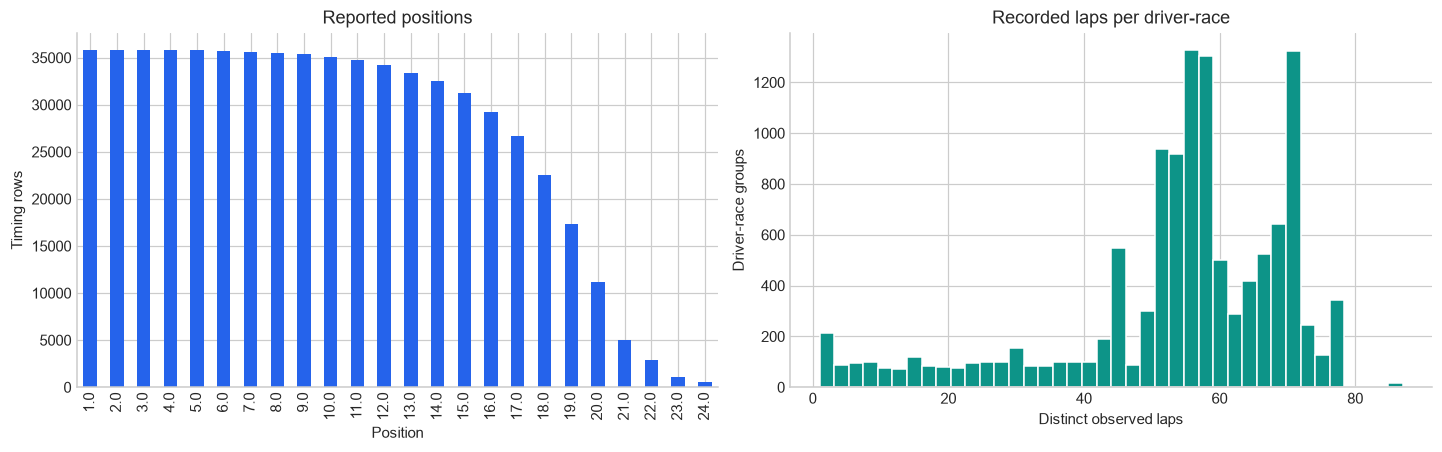

In [13]:
# Duplicate lap keys are already reported above: keep repeated positions separate.
known_positions = df.loc[df["position"].notna()]
repeated_position_mask = known_positions.duplicated(race_key + ["lap", "position"], keep=False)
print(f"Rows sharing a non-null position on the same race lap: {repeated_position_mask.sum():,}")
display(known_positions.loc[repeated_position_mask, lap_key + ["position", "lap_time"]].head(20))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
known_positions["position"].value_counts().sort_index().plot.bar(ax=axes[0], color="#2563eb")
driver_race_summary["distinct_laps"].plot.hist(bins=40, ax=axes[1], color="#0d9488", edgecolor="white")
axes[0].set(title="Reported positions", xlabel="Position", ylabel="Timing rows")
axes[1].set(title="Recorded laps per driver-race", xlabel="Distinct observed laps", ylabel="Driver-race groups")
plt.show()

## 9. Explore one race in detail

Change `selected_season` and `selected_round` below to inspect another race.
The default is the last observed race in the data, not a claim about the
current calendar. The selected drivers are simply the two with the most
recorded laps in that race; this CSV does not contain team membership.

The first panel shows the full timing range. The second zooms to central
durations without deleting observations. Equal lap numbers are not guaranteed
to represent equal clock times when drivers have been lapped.

2026, round 20: Brazilian Grand Prix


,recorded_laps,first_lap,last_lap,median_seconds,missing_positions
driver_id,,,,,
antonelli,71,1,71,77.656,0
max_verstappen,71,1,71,77.228,0
lawson,71,1,71,78.665,0
leclerc,71,1,71,78.487,0
hadjar,71,1,71,76.938,0
russell,71,1,71,78.042,0
piastri,71,1,71,78.229,0
norris,71,1,71,76.407,0
albon,70,1,70,79.522,0


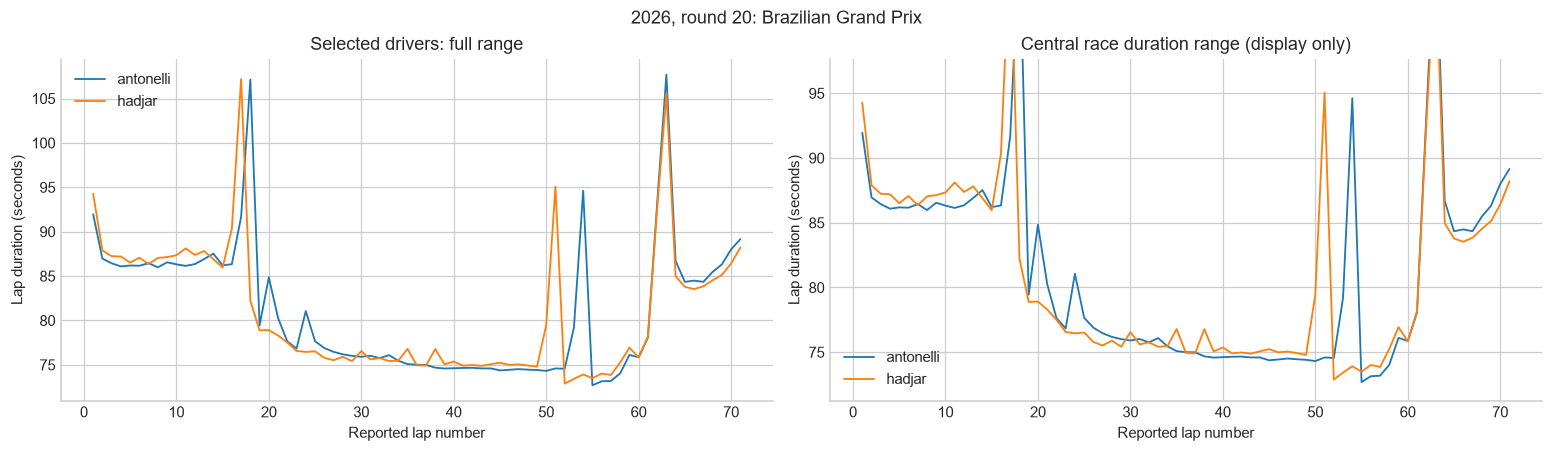

In [14]:
selected_season = int(df["season"].max())
selected_round = int(df.loc[df["season"].eq(selected_season), "round"].max())

race_df = df.loc[df["season"].eq(selected_season) & df["round"].eq(selected_round)].copy()
if race_df.empty:
    raise ValueError("No timings found for the selected season and round.")

race_label = f"{selected_season}, round {selected_round}: {race_df['race_name'].iloc[0]}"
print(race_label)
display(race_df.groupby("driver_id").agg(
    recorded_laps=("lap", "nunique"), first_lap=("lap", "min"), last_lap=("lap", "max"),
    median_seconds=("lap_time_seconds", "median"), missing_positions=("position", lambda s: s.isna().sum()),
).sort_values("recorded_laps", ascending=False))

# Replace this list with driver IDs of interest after checking the table above.
selected_drivers = race_df.groupby("driver_id")["lap"].nunique().nlargest(2).index.tolist()
selected = race_df.loc[race_df["driver_id"].isin(selected_drivers)].sort_values(["driver_id", "lap"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
for driver, timings in selected.groupby("driver_id"):
    for ax in axes:
        ax.plot(timings["lap"], timings["lap_time_seconds"], label=driver, linewidth=1.2)
race_positive_times = race_df.loc[race_df["lap_time_seconds"].gt(0), "lap_time_seconds"]
if not race_positive_times.empty:
    race_low, race_high = race_positive_times.quantile([.01, .95])
    padding = max((race_high - race_low) * .1, 1)
    axes[1].set_ylim(max(0, race_low - padding), race_high + padding)
for ax in axes:
    ax.set(xlabel="Reported lap number", ylabel="Lap duration (seconds)")
    ax.legend()
axes[0].set_title("Selected drivers: full range")
axes[1].set_title("Central race duration range (display only)")
fig.suptitle(race_label)
plt.show()

### Race-wide slow laps and opening-lap context

Race-lap medians can expose shared slow periods, but they cannot label a
Safety Car, red flag, or weather event without supporting data. Each point
aggregates whichever drivers have a reported timing at that lap number.
Opening laps are described separately because starts affect their durations.

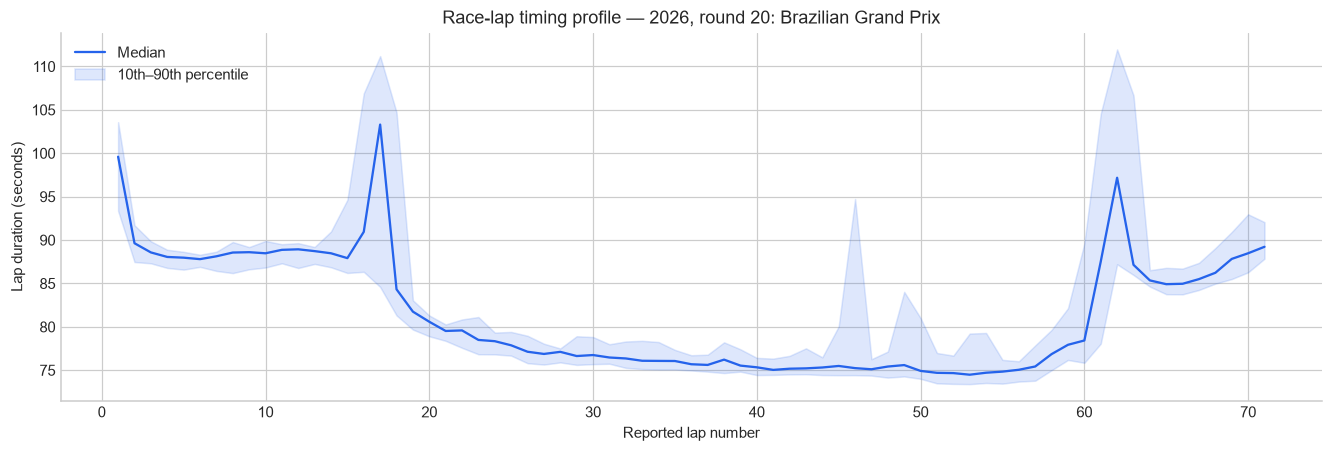

,timings,median,p10,p90
lap,,,,
17,21,103.301,84.597,111.192
1,21,99.599,93.357,103.578
62,20,97.173,87.206,111.961
16,21,90.944,86.336,106.893
2,21,89.631,87.468,91.699
71,8,89.221,87.849,92.059
12,21,88.930,86.777,89.638
11,21,88.869,87.316,89.516
13,21,88.722,87.245,89.196


,timings,median_seconds,p95_seconds
lap_group,,,
Later laps,627358,90.327,120.953
Opening lap,11935,104.651,156.178


In [15]:
race_lap_profile = race_df.groupby("lap")["lap_time_seconds"].agg(
    timings="count", median="median",
    p10=lambda values: values.quantile(.10), p90=lambda values: values.quantile(.90),
)
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(race_lap_profile.index, race_lap_profile["median"], color="#2563eb", label="Median")
ax.fill_between(race_lap_profile.index.to_numpy(dtype=float),
                race_lap_profile["p10"].to_numpy(dtype=float),
                race_lap_profile["p90"].to_numpy(dtype=float),
                color="#2563eb", alpha=.15, label="10th–90th percentile")
ax.set(title=f"Race-lap timing profile — {race_label}", xlabel="Reported lap number",
       ylabel="Lap duration (seconds)")
ax.legend()
plt.show()
display(race_lap_profile.nlargest(10, "median"))

opening_lap_summary = (df.assign(lap_group=df["lap"].eq(1).map({True: "Opening lap", False: "Later laps"}))
    .groupby("lap_group")["lap_time_seconds"]
    .agg(timings="count", median_seconds="median", p95_seconds=lambda values: values.quantile(.95)))
display(opening_lap_summary)

## 10. Findings and next steps

The summary below is calculated from the current CSV, so counts update when
the source changes. It distinguishes internal checks from decisions about
which laps are suitable for pace analysis.

In [16]:
missing_details = "; ".join(
    f"`{column}`: {int(row['missing']):,} ({row['missing_pct']:.2f}%)"
    for column, row in missing_summary.iterrows() if row["missing"] > 0
) or "none"
first_date = df["race_date_parsed"].min()
last_date = df["race_date_parsed"].max()
display(Markdown(f"""
**Current snapshot**

- {len(df):,} timing rows; {len(df[race_key].drop_duplicates()):,} observed races;
  {df['driver_id'].nunique():,} drivers; {df['circuit_id'].nunique():,} circuit IDs.
- Parsed date range: {first_date:%Y-%m-%d} to {last_date:%Y-%m-%d}.
- Exact duplicate extra rows: {int(exact_duplicate_mask.sum()):,}.
  Rows belonging to repeated lap keys: {int(repeated_key_mask.sum()):,}.
- Missing values: {missing_details}.
- Missing or invalid timing durations: {int(invalid_time_mask.sum()):,}.
- Internal sequence gaps: {len(gaps):,}; driver-race groups starting after lap 1: {len(late_starts):,}.
- Durations above 300 seconds: {int(valid_times.gt(300).sum()):,}; these are review candidates.
- Rows retained in the analysis copy: {len(df):,} of {len(raw):,} source rows.
"""))

assert len(df) == len(raw), "EDA should retain every source row."
assert raw.columns.isin(["lap_time_seconds", "race_date_parsed"]).sum() == 0


**Current snapshot**

- 639,293 timing rows; 588 observed races;
  149 drivers; 42 circuit IDs.
- Parsed date range: 1996-03-10 to 2026-11-08.
- Exact duplicate extra rows: 0.
  Rows belonging to repeated lap keys: 0.
- Missing values: `race_start_time`: 150,951 (23.61%); `position`: 16 (0.00%).
- Missing or invalid timing durations: 0.
- Internal sequence gaps: 10; driver-race groups starting after lap 1: 3.
- Durations above 300 seconds: 787; these are review candidates.
- Rows retained in the analysis copy: 639,293 of 639,293 source rows.


**Recommendations for a later cleaning step**

1. Retain the original duration text alongside the numeric seconds added here.
   Consider a nullable integer type for positions in a later cleaning step.
2. Keep missing start times and positions explicit. Do not invent replacement
   positions or interpolate absent lap timings.
3. Review repeated keys, metadata conflicts, unusual durations, and sequence
   gaps before choosing a rule for a processed dataset.
4. Define pace exclusions separately from data-quality errors. A valid long
   timing, an opening lap, or a pit-related lap may be unsuitable for a
   particular comparison without being an invalid record.
5. Compare within a specific race and circuit context. Global duration
   thresholds and pooled driver averages can be misleading.

**Limits of this dataset**

This CSV does not identify teams, tyre compounds, pit stops, weather, flags,
or the official reason for an unusual timing. Internal consistency cannot
confirm that a timing belongs to the correct driver. It also cannot establish
full calendar coverage or detect every missing trailing lap. No such labels,
corrections, or causal claims are inferred here.

The source CSV remains unchanged. The next section exports a processed copy
with numeric lap durations; the quality-review findings above remain applicable.

## 11. Save the processed lap timings

Save the processed copy to **`data/processed/laps/lap_times.csv`** so the next
notebook can read `lap_time_seconds` directly. Keep every original column and
row, and append the duration in seconds, rounded to the source precision of
three decimal places. The temporary `race_date_parsed` helper is not exported.

Run the earlier cells first, then run the cell below (or use **Run All**).
The folder is created if needed; rerunning this cell regenerates the same
output file. Missing values and unusual timings are retained for later review.
The original `data/raw/lap_times.csv` is not modified.

In the next notebook, read the file with
`pd.read_csv(project_root / "data" / "processed" / "laps" / "lap_times.csv", low_memory=False)`.


In [17]:
processed_path = project_root / "data" / "processed" / "laps" / "lap_times.csv"
processed_path.parent.mkdir(parents=True, exist_ok=True)

# Export original fields plus numeric duration, without EDA-only helper columns.
processed_laps = df.loc[:, [*raw.columns, "lap_time_seconds"]].copy()
processed_laps["lap_time_seconds"] = processed_laps["lap_time_seconds"].round(3)
assert len(processed_laps) == len(raw), "The export must retain every source row."
processed_laps.to_csv(processed_path, index=False, encoding="utf-8")

print(f"Saved: {processed_path.relative_to(project_root)}")
print(f"Rows: {len(processed_laps):,}; columns: {len(processed_laps.columns)}")
display(processed_laps[["lap_time", "lap_time_seconds"]].head())


Saved: data\processed\laps\lap_times.csv
Rows: 639,293; columns: 12


,lap_time,lap_time_seconds
0,1:43.702,103.702
1,1:44.243,104.243
2,1:44.981,104.981
3,1:45.188,105.188
4,1:46.506,106.506
